# OmicOS_7 Non-HE Analysis

Bypasses new H&E queue work and completes predicted ST plus validation analyses.

# Pre define


In [19]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

ROOT = Path("/data/hulei/OmicOS")
OUT = ROOT / "OmicOS_7"
FIG = OUT / "outputs" / "figures"
PANEL = FIG / "panels"
TAB = OUT / "outputs" / "tables"
LOG = OUT / "outputs" / "logs"
REP = OUT / "outputs" / "report"
for d in [FIG, PANEL, TAB, LOG, REP]:
    d.mkdir(parents=True, exist_ok=True)

P3 = ROOT / "OmicOS_3" / "outputs"
CODEX = ROOT / "codex" / "he2st_lung_visium_hd"

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "Liberation Sans"],
    "font.size": 10.5,
    "axes.titlesize": 11.2,
    "axes.labelsize": 10.0,
    "xtick.labelsize": 8.6,
    "ytick.labelsize": 8.6,
    "legend.fontsize": 8.0,
    "axes.linewidth": 0.7,
    "axes.titlepad": 3.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

GROUP_COLORS = {
    "tumor": "#d62728",
    "immune": "#2ca02c",
    "stromal": "#ffbf00",
    "vascular": "#17becf",
    "other": "#888888",
}


def read_csv(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def panel_label(ax, label):
    ax.text(
        -0.065,
        1.03,
        str(label).lower(),
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="bottom",
        ha="left",
    )


def clean_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_facecolor("white")


def robust_norm(values):
    values = pd.Series(values).astype(float)
    lo, hi = values.quantile([0.02, 0.98])
    if hi <= lo:
        hi = values.max() if values.max() > lo else lo + 1.0
    return ((values - lo) / (hi - lo)).clip(0, 1)


def spatial_binary(ax, df, column, title, true_color="#d62728", false_color="#cfcfcf"):
    values = df[column].astype(bool)
    colors = np.where(values, true_color, false_color)
    ax.scatter(df["center_x"], df["center_y"], c=colors, s=1.15, linewidths=0, rasterized=True)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    clean_axis(ax)
    ax.set_title(title)
    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", color="none", markerfacecolor=true_color, markersize=5, label="cancer-enriched"),
            Line2D([0], [0], marker="o", color="none", markerfacecolor=false_color, markersize=5, label="other tiles"),
        ],
        frameon=False,
        loc="lower right",
    )


def finish_notebook_panel(fig, section, panel, name):
    out_dir = PANEL / section
    out_dir.mkdir(parents=True, exist_ok=True)
    outputs = []
    for suffix in ["pdf", "png"]:
        out = out_dir / f"{panel}_{name}.{suffix}"
        fig.savefig(out, bbox_inches="tight", pad_inches=0.03)
        outputs.append(out)
        print(f"saved panel: {out}")
    display(fig)
    plt.close(fig)
    return outputs


In [20]:
def spatial_tumor_immune_on_he(
    ax,
    df,
    title="Predicted ST tumor and immune programs",
    x="center_x",
    y="center_y",
    quantile_threshold=0.65,
    size=5.0,
    alpha=0.70,
    he_alpha=0.55,
    he_stride=32,
    fontsize=18,
    draw_border=True,
    border_pad_frac=0.006,
    legend_space_frac=0.28,
):
    # 读取 H&E thumbnail
    info = btf_page_info()
    thumb = build_btf_thumbnail(stride=he_stride)

    # 空间坐标范围
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()
    dx = x1 - x0
    dy = y1 - y0

    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac

    # 画 H&E 背景
    ax.imshow(
        thumb,
        extent=(0, info["width"], info["height"], 0),
        alpha=he_alpha,
        zorder=0,
    )

    # robust-normalized scores
    tumor = robust_norm(df["epithelial_tumor"])
    immune = robust_norm(df["immune"])

    keep_tumor = tumor >= tumor.quantile(quantile_threshold)
    keep_immune = immune >= immune.quantile(quantile_threshold)

    # 先画 immune，再画 tumor
    sc_immune = ax.scatter(
        df.loc[keep_immune, x],
        df.loc[keep_immune, y],
        c=immune.loc[keep_immune],
        cmap="Blues",
        vmin=0,
        vmax=1,
        s=size,
        alpha=alpha,
        linewidths=0,
        rasterized=True,
        zorder=2,
    )

    sc_tumor = ax.scatter(
        df.loc[keep_tumor, x],
        df.loc[keep_tumor, y],
        c=tumor.loc[keep_tumor],
        cmap="Reds",
        vmin=0,
        vmax=1,
        s=size,
        alpha=alpha,
        linewidths=0,
        rasterized=True,
        zorder=3,
    )

    if draw_border:
        ax.add_patch(
            Rectangle(
                (x0, y0),
                dx,
                dy,
                fill=False,
                edgecolor="black",
                linewidth=1.2,
                zorder=10,
                clip_on=False,
            )
        )

    # 只显示 tile footprint 附近，而不是整张 WSI
    ax.set_xlim(x0 - pad_x, x1 + pad_x + dx * legend_space_frac)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=fontsize, pad=8)
    clean_axis(ax)

    return sc_tumor, sc_immune

In [21]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf
Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
✅ plot_set complete.



# Figure A


In [22]:
def add_tumor_immune_colorbars(
    fig,
    sc_tumor,
    sc_immune,
    x0=0.79,
    y0=0.62,
    width=0.12,
    height=0.025,
    y_gap=0.16,
    fontsize=14,
):
    items = [
        ("Tumor signature", "#d62728", sc_tumor),
        ("Immune signature", "#2C7FB8", sc_immune),
    ]

    for i, (title, color, sc) in enumerate(items):
        cax = fig.add_axes([x0, y0 - i * y_gap, width, height])
        cax._skip_panel = True

        cb = fig.colorbar(sc, cax=cax, orientation="horizontal")
        cb.ax.tick_params(
            labelsize=fontsize * 0.80,
            length=3,
            width=1.0,
            pad=1,
        )
        cb.set_ticks([0, 0.5, 1.0])
        cb.set_ticklabels(["0", "0.5", "1"])

        cax.set_title(
            title,
            fontsize=fontsize,
            color=color,
            pad=8,
        )

        for spine in cax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
            spine.set_edgecolor("black")

import math
import tifffile
from pathlib import Path

# 当前 notebook 里 ROOT 已经是 /data/hulei/OmicOS
WSI = ROOT / "Data" / "Visium_HD_Human_Lung_Cancer_Fixed_Frozen_tissue_image.btf"

# 给 H&E thumbnail 单独建缓存目录
ART = OUT / "outputs" / "artifacts"
ART.mkdir(parents=True, exist_ok=True)


def btf_page_info():
    with tifffile.TiffFile(str(WSI)) as tf:
        page = tf.pages[0]
        return {
            "width": int(page.imagewidth),
            "height": int(page.imagelength),
            "tilewidth": int(page.tilewidth),
            "tilelength": int(page.tilelength),
        }


def build_btf_thumbnail(stride=32):
    cache = ART / f"he_btf_thumbnail_stride{stride}_omicos7.npy"

    if cache.exists():
        return np.load(cache)

    with tifffile.TiffFile(str(WSI)) as tf, WSI.open("rb") as fh:
        page = tf.pages[0]

        tw, th = page.tilewidth, page.tilelength
        nx = math.ceil(page.imagewidth / tw)
        ny = math.ceil(page.imagelength / th)

        sy = math.ceil(th / stride)
        sx = math.ceil(tw / stride)

        thumb = np.zeros((ny * sy, nx * sx, 3), dtype=np.uint8)

        for idx, (off, bc) in enumerate(zip(page.dataoffsets, page.databytecounts)):
            fh.seek(off)
            tile = np.frombuffer(fh.read(bc), dtype=np.uint8).reshape(th, tw, 3)

            yy = idx // nx
            xx = idx % nx

            mini = tile[::stride, ::stride, :]

            thumb[
                yy * sy:yy * sy + mini.shape[0],
                xx * sx:xx * sx + mini.shape[1],
                :
            ] = mini

    np.save(cache, thumb)
    return thumb

saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/a_tumor_immune_on_he.pdf
saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/a_tumor_immune_on_he.png


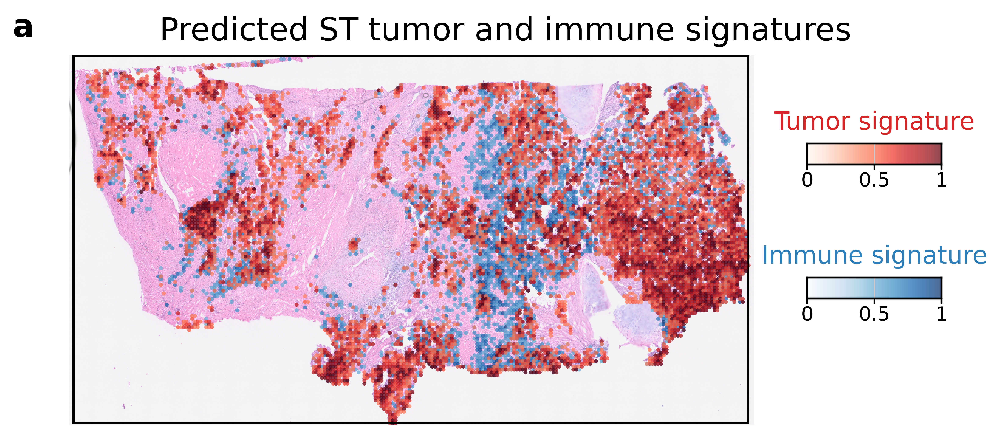

[PosixPath('/data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/a_tumor_immune_on_he.pdf'),
 PosixPath('/data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/a_tumor_immune_on_he.png')]

In [23]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
g32["he_cancer_region_proxy_score"] = robust_norm(g32["epithelial_tumor"])
g32["he_cancer_region_proxy"] = g32["he_cancer_region_proxy_score"] >= g32["he_cancer_region_proxy_score"].quantile(0.75)
g32["tumor_immune_interface_score"] = robust_norm(g32["epithelial_tumor"]) * robust_norm(g32["immune"])


fig, ax = plt.subplots(figsize=(8.8, 6.6))

panel_label(ax, "a")

sc_tumor, sc_immune = spatial_tumor_immune_on_he(
    ax,
    g32,
    title="Predicted ST tumor and immune signatures",
    quantile_threshold=0.65,
    size=5.0,
    alpha=0.72,
    he_alpha=0.55,
    he_stride=32,
    fontsize=18,
)

add_tumor_immune_colorbars(
    fig,
    sc_tumor,
    sc_immune,
    x0=0.84,
    y0=0.62,
    width=0.12,
    height=0.025,
    y_gap=0.16,
    fontsize=14,
)

finish_notebook_panel(
    fig,
    "non_he_analysis",
    "a",
    "tumor_immune_on_he"
)

In [24]:
def add_main_colorbars(
    fig,
    sc_tumor,
    sc_immune,
    x0=0.79,
    y0=0.62,
    width=0.12,
    height=0.025,
    y_gap=0.16,
    fontsize=14,
):
    items = [
        ("Tumor program", "#d62728", sc_tumor),
        ("Immune program", "#2C7FB8", sc_immune),
    ]

    for i, (title, color, sc) in enumerate(items):
        cax = fig.add_axes([x0, y0 - i * y_gap, width, height])
        cax._skip_panel = True

        cb = fig.colorbar(sc, cax=cax, orientation="horizontal")
        cb.ax.tick_params(labelsize=fontsize * 0.80, length=3, width=1.0, pad=1)
        cb.set_ticks([0, 0.5, 1.0])
        cb.set_ticklabels(["0", "0.5", "1"])

        cax.set_title(title, fontsize=fontsize, color=color, pad=8)

        for spine in cax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
            spine.set_edgecolor("black")

# Figure B


saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/b_he_cancer_region_proxy.pdf
saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/b_he_cancer_region_proxy.png


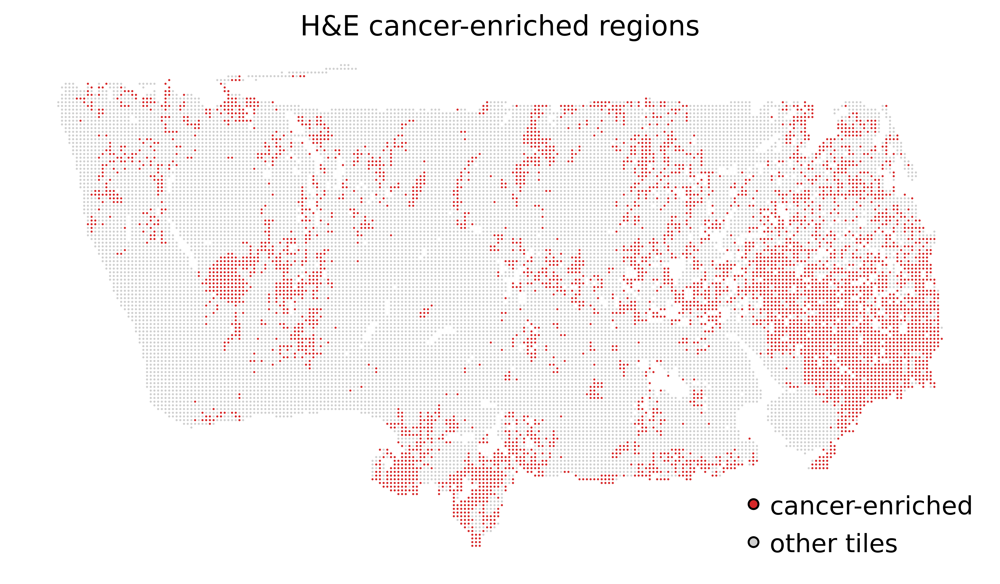

[PosixPath('/data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/b_he_cancer_region_proxy.pdf'),
 PosixPath('/data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/b_he_cancer_region_proxy.png')]

In [25]:
fig, ax = plt.subplots(figsize=(8.8, 6.6))
spatial_binary(ax, g32, "he_cancer_region_proxy", "H&E cancer-enriched regions")
finish_notebook_panel(fig, "non_he_analysis", "b", "he_cancer_region_proxy")


# Figure C


saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/c_full_data_gene_mean_correlation.pdf
saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/c_full_data_gene_mean_correlation.png


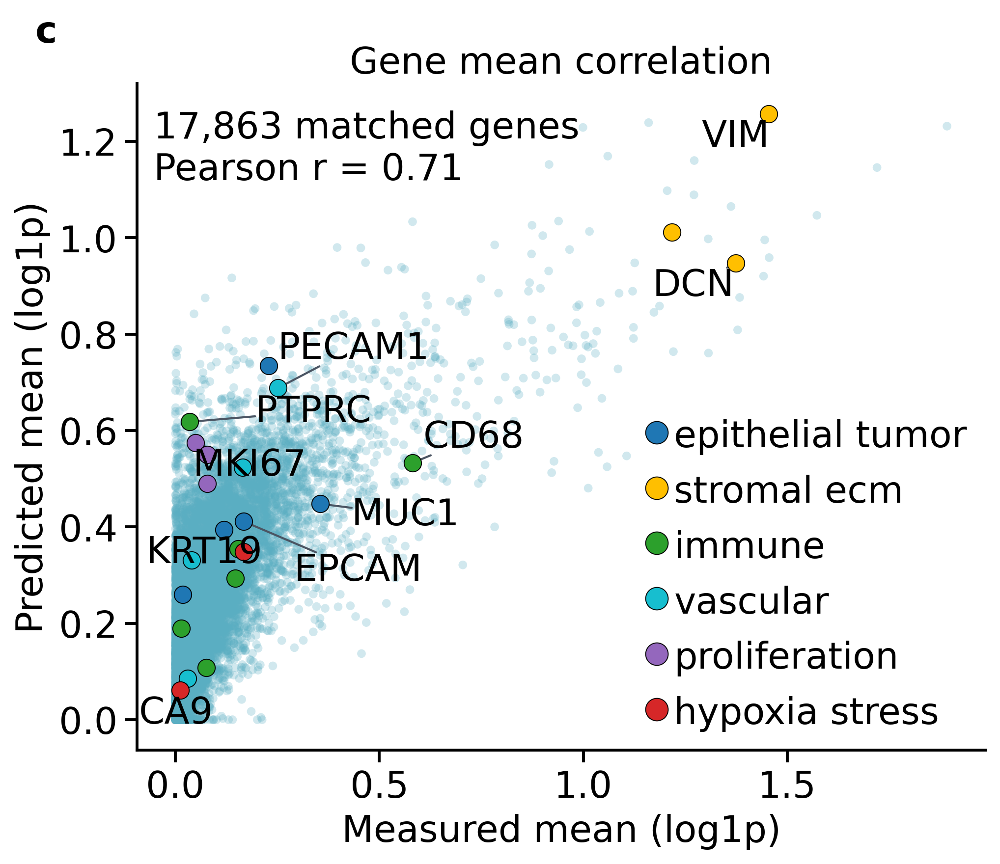

saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/c_full_data_gene_variance_correlation.pdf
saved panel: /data/hulei/OmicOS/OmicOS_7/outputs/figures/panels/non_he_analysis/c_full_data_gene_variance_correlation.png


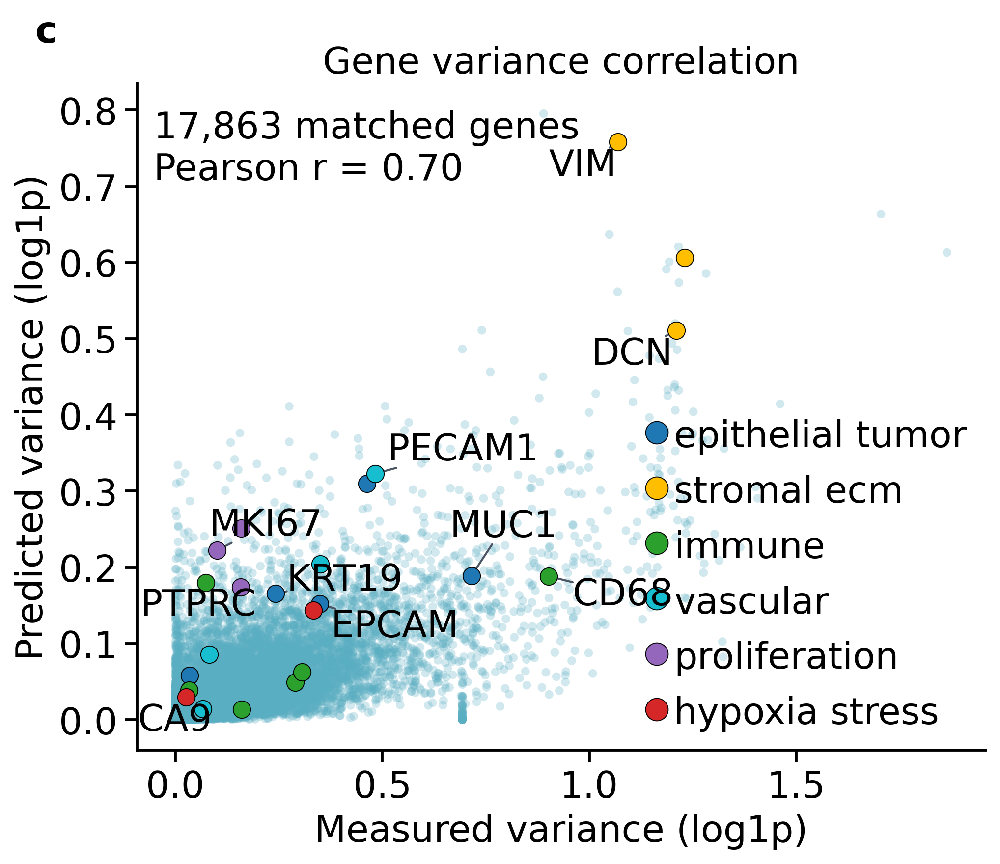

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text
from IPython.display import display
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

ROOT = Path("/data/hulei/OmicOS")
OUT = ROOT / "OmicOS_7"
FIG_DIR = OUT / "outputs" / "figures" / "panels" / "non_he_analysis"
TAB_DIR = OUT / "outputs" / "tables"
for path in [FIG_DIR, TAB_DIR]:
    path.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "Liberation Sans"],
        "font.size": 18,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "axes.linewidth": 1.4,
        "axes.titlepad": 5.0,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

MARKER_GROUPS = {
    "epithelial_tumor": ["EPCAM", "KRT19", "KRT8", "KRT18", "MUC1", "SOX2"],
    "stromal_ecm": ["COL1A1", "COL1A2", "DCN", "LUM", "VIM"],
    "immune": ["PTPRC", "CD3D", "CD3E", "CD68", "LST1", "MS4A1"],
    "vascular": ["PECAM1", "VWF", "KDR", "EMCN"],
    "proliferation": ["MKI67", "TOP2A", "PCNA"],
    "hypoxia_stress": ["VEGFA", "CA9", "HIF1A"],
}

MARKER_COLORS = {
    "epithelial_tumor": "#1f77b4",
    "stromal_ecm": "#ffbf00",
    "immune": "#2ca02c",
    "vascular": "#17becf",
    "proliferation": "#9467bd",
    "hypoxia_stress": "#d62728",
}

LABEL_GENES = ["EPCAM", "KRT19", "MUC1", "VIM", "DCN", "PTPRC", "CD68", "PECAM1", "MKI67", "CA9"]
BACKGROUND_GENE_COLOR = "#5aaec2"


def panel_label(ax, label: str) -> None:
    ax.text(
        -0.12,
        1.05,
        str(label).lower(),
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="bottom",
        ha="left",
    )


def plot_calibration_axis(ax, frame: pd.DataFrame, x_col: str, y_col: str, title: str, subtitle: str) -> None:
    x = np.log1p(np.clip(frame[x_col].to_numpy(dtype=float), 0, None))
    y = np.log1p(np.clip(frame[y_col].to_numpy(dtype=float), 0, None))
    keep = np.isfinite(x) & np.isfinite(y)
    x = x[keep]
    y = y[keep]

    ax.scatter(
        x,
        y,
        s=18,
        c=BACKGROUND_GENE_COLOR,
        marker="o",
        edgecolors="none",
        alpha=0.28,
        rasterized=True,
        zorder=1,
    )

    ax.set_title(title, loc="center", fontweight="normal")
    ax.text(0.02, 0.96, subtitle, transform=ax.transAxes, ha="left", va="top", fontsize=18)
    ax.set_xlabel(f"Measured {x_col.replace('measured_', '').replace('_', ' ')} (log1p)")
    ax.set_ylabel(f"Predicted {y_col.replace('predicted_', '').replace('_', ' ')} (log1p)")
    ax.grid(False)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", width=1.4, length=6)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(1.4)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)


def overlay_markers(ax, frame: pd.DataFrame, x_col: str, y_col: str) -> None:
    for group, genes in MARKER_GROUPS.items():
        sub = frame[frame["symbol"].isin(genes)]
        if sub.empty:
            continue
        ax.scatter(
            np.log1p(np.clip(sub[x_col], 0, None)),
            np.log1p(np.clip(sub[y_col], 0, None)),
            s=72,
            facecolor=MARKER_COLORS[group],
            edgecolor="black",
            linewidth=0.45,
            zorder=5,
            label=group.replace("_", " "),
        )

    label_frame = frame[frame["symbol"].isin(LABEL_GENES)]
    texts = []
    label_x = []
    label_y = []
    for _, row in label_frame.iterrows():
        x = np.log1p(max(float(row[x_col]), 0))
        y = np.log1p(max(float(row[y_col]), 0))
        texts.append(ax.text(x, y, row["symbol"], fontsize=18, ha="center", va="center", zorder=6))
        label_x.append(x)
        label_y.append(y)

    if texts:
        adjust_text(
            texts,
            x=label_x,
            y=label_y,
            target_x=label_x,
            target_y=label_y,
            ax=ax,
            expand=(1.15, 1.35),
            force_text=(0.35, 0.65),
            force_static=(0.15, 0.35),
            force_pull=(0.02, 0.02),
            max_move=(18, 18),
            min_arrow_len=0,
            iter_lim=600,
            arrowprops={
                "arrowstyle": "-",
                "color": "#4b5563",
                "lw": 1.0,
                "shrinkA": 0,
                "shrinkB": 3,
            },
        )


def marker_legend_handles() -> list[Line2D]:
    return [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=color,
            markeredgecolor="black",
            markeredgewidth=0.45,
            markersize=11,
            label=group.replace("_", " "),
        )
        for group, color in MARKER_COLORS.items()
    ]


def save_single_calibration_figure(
    merged: pd.DataFrame,
    x_col: str,
    y_col: str,
    title: str,
    subtitle: str,
    output_stem: str,
) -> None:
    fig, ax = plt.subplots(figsize=(7.2, 6.2), constrained_layout=False)
    panel_label(ax, "c")
    plot_calibration_axis(ax, merged, x_col, y_col, title, subtitle)
    overlay_markers(ax, merged, x_col, y_col)
    ax.legend(
        handles=marker_legend_handles(),
        loc="lower right",
        frameon=False,
        ncol=1,
        handlelength=0.8,
        handletextpad=0.08,
    )
    fig.subplots_adjust(left=0.16, right=0.96, bottom=0.15, top=0.88)

    for suffix in ["pdf", "png"]:
        out = FIG_DIR / f"{output_stem}.{suffix}"
        fig.savefig(out, bbox_inches="tight", pad_inches=0.03)
        print(f"saved panel: {out}")
    display(fig)
    plt.close(fig)


merged = pd.read_csv(TAB_DIR / "full_data_predicted_vs_visium_gene_calibration_omicos7.csv")

mean_x = np.log1p(np.clip(merged["measured_mean"].to_numpy(dtype=float), 0, None))
mean_y = np.log1p(np.clip(merged["predicted_mean"].to_numpy(dtype=float), 0, None))
var_x = np.log1p(np.clip(merged["measured_variance"].to_numpy(dtype=float), 0, None))
var_y = np.log1p(np.clip(merged["predicted_variance"].to_numpy(dtype=float), 0, None))

mean_subtitle = f"{len(merged):,} matched genes\nPearson r = {pearsonr(mean_x, mean_y)[0]:.2f}"
var_subtitle = f"{len(merged):,} matched genes\nPearson r = {pearsonr(var_x, var_y)[0]:.2f}"

save_single_calibration_figure(
    merged,
    "measured_mean",
    "predicted_mean",
    "Gene mean correlation",
    mean_subtitle,
    "c_full_data_gene_mean_correlation",
)
save_single_calibration_figure(
    merged,
    "measured_variance",
    "predicted_variance",
    "Gene variance correlation",
    var_subtitle,
    "c_full_data_gene_variance_correlation",
)


# Figure F
